# DL EXPERIMENT 2: Comparative Study of Activation Functions and Optimizers


## PART A: VISUALIZATION OF ACTIVATION FUNCTIONS

In [1]:
# Import necessary libraries
print("24BAD004")
print("K ADHITHYA")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

24BAD004
K ADHITHYA


In [2]:
x = np.linspace(-10, 10, 200)

### Sigmoid Activation Function

In [3]:
# Sigmoid Activation Function
y_sigmoid = tf.keras.activations.sigmoid(x)

### Tanh Activation Function

In [4]:
# Tanh Activation Function
y_tanh = tf.keras.activations.tanh(x)

### ReLU Activation Function

In [5]:
# ReLU Activation Function
y_relu = tf.keras.activations.relu(x)

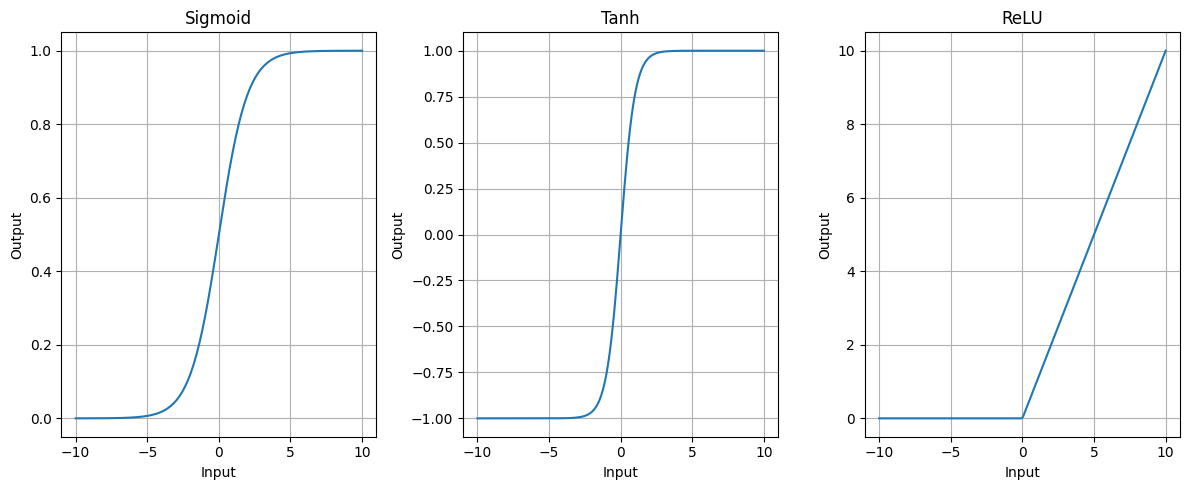

In [6]:
# Plot all activation functions
plt.figure(figsize=(12, 5))

# Sigmoid
plt.subplot(1, 3, 1)
plt.plot(x, y_sigmoid)
plt.title("Sigmoid")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

# Tanh
plt.subplot(1, 3, 2)
plt.plot(x, y_tanh)
plt.title("Tanh")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

# ReLU
plt.subplot(1, 3, 3)
plt.plot(x, y_relu)
plt.title("ReLU")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

plt.tight_layout()
plt.show()

## PART B: PERFORMANCE COMPARISON OF ACTIVATION FUNCTIONS

In [7]:
print("24BAD004")
print("K ADHITHYA")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

24BAD004
K ADHITHYA


In [8]:
# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Display the shape of the dataset
print("Features:", X.shape)
print("Labels:", y.shape)
print("Class names:", data.target_names)

Features: (569, 30)
Labels: (569,)
Class names: ['malignant' 'benign']


### Preprocessing the Dataset

In [9]:
# Spliting into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scaling features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Display the shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Labels: (455,)
Testing Labels: (114,)


### Build and Compile the ANN

In [10]:
# Function to build and compile the ANN model
def build_model(activation):
    model = Sequential([
        Dense(32, activation=activation, input_shape=(X_train.shape[1],)),
        Dense(16, activation=activation),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

activation_functions = ["relu", "sigmoid", "tanh"]
history_dict = {}
evaluation_dict = {}

### Train the ANN

In [11]:
for activation in activation_functions:
    print("-" * 50)
    print(f"Training Model with {activation.upper()} Activation")
    print("-" * 50)

    # Build model
    model = build_model(activation)

    # Train model
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_test, y_test),
        epochs=50,
        batch_size=32,
        verbose=1
    )

    # Evaluate model
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    # Store results
    history_dict[activation] = history
    evaluation_dict[activation] = {
        "loss": loss,
        "accuracy": accuracy
    }

    print(f"\nFinal Test Loss : {loss:.4f}")
    print(f"Final Test Accuracy : {accuracy:.4f}\n")

--------------------------------------------------
Training Model with RELU Activation
--------------------------------------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 112ms/step - accuracy: 0.7978 - loss: 0.5532 - val_accuracy: 0.8860 - val_loss: 0.4358
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9231 - loss: 0.3437 - val_accuracy: 0.9211 - val_loss: 0.3121
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9385 - loss: 0.2433 - val_accuracy: 0.9386 - val_loss: 0.2359
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9538 - loss: 0.1844 - val_accuracy: 0.9386 - val_loss: 0.1892
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9604 - loss: 0.1504 - val_accuracy: 0.9386 - val_loss: 0.1601
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9626 - loss: 0.1279 - val_accuracy: 0.9474 - val_loss: 0.1433
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9692 - loss: 0.1121 - val_accuracy: 0.9561 - val_loss: 0.1303
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9736 - loss: 0.0998 - val_accuracy: 0.9561 - val_los

### Comparison Table

In [ ]:
print("\nActivation Function Comparison")
print("-" * 50)

for activation in activation_functions:
    print(
        f"{activation.upper():10} "
        f"Accuracy: {evaluation_dict[activation]['accuracy']:.4f} | "
        f"Loss: {evaluation_dict[activation]['loss']:.4f}")


Activation Function Comparison
--------------------------------------------------
RELU       Accuracy: 0.9561 | Loss: 0.0921
SIGMOID    Accuracy: 0.9561 | Loss: 0.0928
TANH       Accuracy: 0.9561 | Loss: 0.0945


### Visualizations

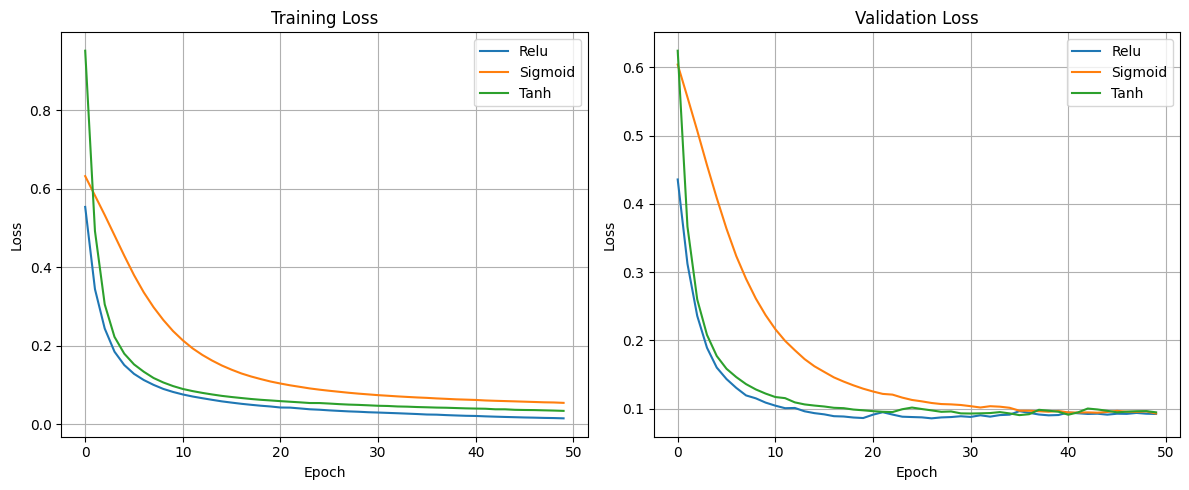

In [13]:
plt.figure(figsize=(12, 5))

# Training Loss
plt.subplot(1, 2, 1)
for activation in activation_functions:
    plt.plot(
        history_dict[activation].history['loss'],
        label=f'{activation.capitalize()}'
    )
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Validation Loss
plt.subplot(1, 2, 2)
for activation in activation_functions:
    plt.plot(
        history_dict[activation].history['val_loss'],
        label=f'{activation.capitalize()}'
    )
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

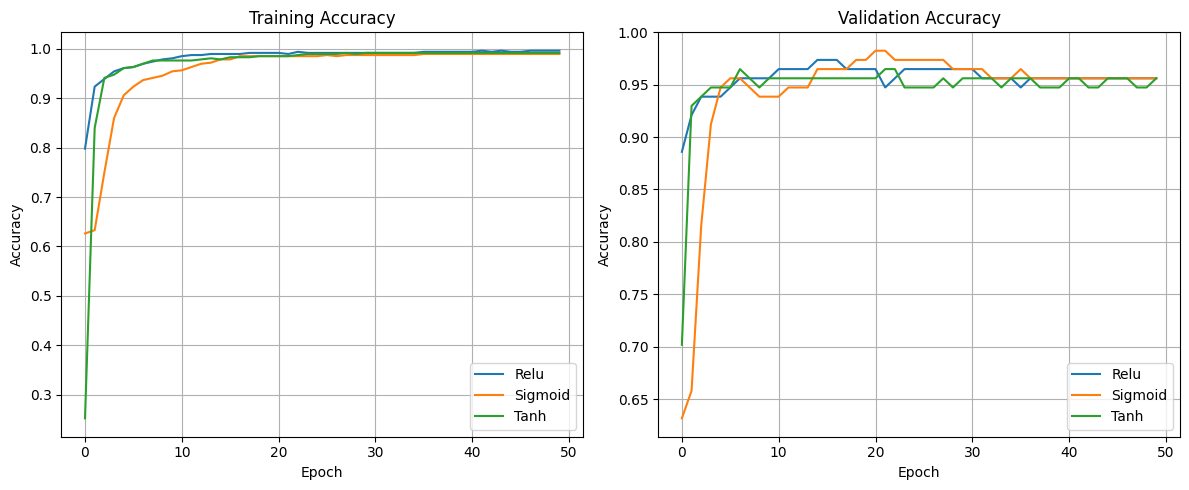

In [14]:
plt.figure(figsize=(12, 5))

# Training Accuracy
plt.subplot(1, 2, 1)
for activation in activation_functions:
    plt.plot(
        history_dict[activation].history['accuracy'],
        label=f'{activation.capitalize()}'
    )
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 2, 2)
for activation in activation_functions:
    plt.plot(
        history_dict[activation].history['val_accuracy'],
        label=f'{activation.capitalize()}'
    )
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Observation:** ReLU generally achieves the highest accuracy and converges fastest since it avoids the vanishing gradient problem. Sigmoid comes close but converges a little slower. Tanh, while zero-centered, still saturates at both ends and tends to lag slightly behind the other two.

## PART C: COMPARISON OF OPTIMIZATION ALGORITHMS

In [15]:
# Import optimizers
print("24BAD004")
print("K ADHITHYA")

from tensorflow.keras.optimizers import SGD, RMSprop, Adam

24BAD004
K ADHITHYA


### Build and Compile the ANN

In [16]:
def build_model_c(optimizer):
    model = Sequential([
        Dense(32, activation="relu", input_shape=(X_train.shape[1],)),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

optimizers = {
    "SGD": SGD(),
    "Momentum": SGD(momentum=0.9),
    "RMSprop": RMSprop(),
    "Adam": Adam()
}

history_dict_c = {}
evaluation_dict_c = {}

### Train the ANN

In [17]:
for name, optimizer in optimizers.items():
    print("-" * 50)
    print(f"Training with {name}")
    print("-" * 50)

    model = build_model_c(optimizer)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_test, y_test),
        epochs=50,
        batch_size=32,
        verbose=1
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
    history_dict_c[name] = history
    evaluation_dict_c[name] = {
        "loss": loss,
        "accuracy": accuracy
    }

    print(f"\n{name} Results")
    print(f"Loss : {loss:.4f}")
    print(f"Accuracy : {accuracy:.4f}\n")

--------------------------------------------------
Training with SGD
--------------------------------------------------
Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.6022 - loss: 0.6902 - val_accuracy: 0.7456 - val_loss: 0.5957
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7736 - loss: 0.5812 - val_accuracy: 0.8684 - val_loss: 0.5186
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8593 - loss: 0.5026 - val_accuracy: 0.9123 - val_loss: 0.4603
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8857 - loss: 0.4426 - val_accuracy: 0.9211 - val_loss: 0.4122
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9055 - loss: 0.3914 - val_accuracy: 0.9298 - val_loss: 0.3733
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9209 - loss: 0.3516 - val_accuracy: 0.9386 - val_loss: 0.3405
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9231 - loss: 0.3189 - val_accuracy: 0.9386 - val_loss: 0.31

### Comparison Table

In [18]:
print("\nOptimizer Comparison")
print("-" * 50)

for name in optimizers.keys():
    print(
        f"{name:10} "
        f"Accuracy : {evaluation_dict_c[name]['accuracy']:.4f} | "
        f"Loss : {evaluation_dict_c[name]['loss']:.4f}"
    )


Optimizer Comparison
--------------------------------------------------
SGD        Accuracy : 0.9474 | Loss : 0.1045
Momentum   Accuracy : 0.9561 | Loss : 0.1144
RMSprop    Accuracy : 0.9561 | Loss : 0.1355
Adam       Accuracy : 0.9561 | Loss : 0.1048


### Visualizations

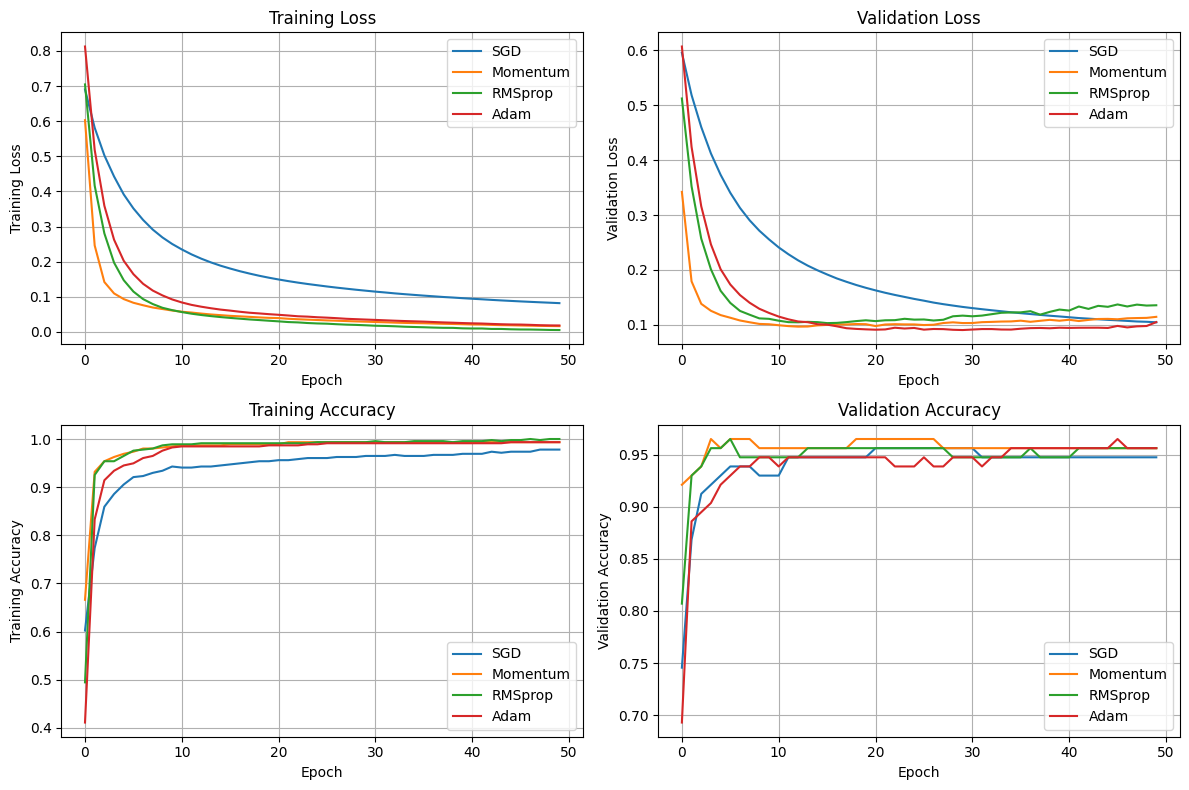

In [19]:
metrics = [('loss', 'Training Loss'),
           ('val_loss', 'Validation Loss'),
           ('accuracy', 'Training Accuracy'),
           ('val_accuracy', 'Validation Accuracy')]

plt.figure(figsize=(12, 8))

for i, (metric, title) in enumerate(metrics, 1):
    plt.subplot(2, 2, i)
    for name, h in history_dict_c.items():
        plt.plot(h.history[metric], label=name)
    plt.title(title)
    plt.ylabel(title)
    plt.xlabel("Epoch")
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

**Observation:** Adam and RMSprop converge the fastest with the lowest loss and highest accuracy, since both use adaptive per-parameter learning rates. Momentum converges faster and more stably than plain SGD, since the momentum term smooths out the update direction. Plain SGD is the slowest of the four, taking the most epochs to reach comparable accuracy.

## PART D: DEEP LEARNING EXPERIMENT MANAGEMENT

In [20]:
print("24BAD004")
print("K ADHITHYA")

import os
from google.colab import drive

drive.mount('/content/drive')

24BAD004
K ADHITHYA
Mounted at /content/drive


### Import Required Libraries

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Load and Prepare the Dataset

In [22]:
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Build the Model

In [23]:
model = Sequential([
    Dense(32, activation="relu", input_shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Compile the Model

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"])

### Train the Model

In [25]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.6396 - loss: 0.7385 - val_accuracy: 0.7368 - val_loss: 0.5551
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8330 - loss: 0.4693 - val_accuracy: 0.9298 - val_loss: 0.3954
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9187 - loss: 0.3374 - val_accuracy: 0.9386 - val_loss: 0.3105
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9429 - loss: 0.2591 - val_accuracy: 0.9386 - val_loss: 0.2548
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9516 - loss: 0.2078 - val_accuracy: 0.9474 - val_loss: 0.2181
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9582 - loss: 0.1721 - val_accuracy: 0.9561 - val_loss: 0.1914
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9648 - loss: 0.1462 - val_accuracy: 0.9474 - val_loss: 0.1721
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9692 - loss: 0.1285 - val_accuracy: 0.9474 - val_loss

### Save the Model

In [26]:
model.save('/content/drive/MyDrive/model.keras')
print("Model saved successfully!")

Model saved successfully!
